# EDA - Exploratory Data Analysis

## 1. Buisness problem or objeactive

### Find the Problem Behinde the Why Customer's are not visited to our Mall.

## 2. import the Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Import The Dataset

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")

print("Path to dataset files:", path)

c:\Users\Shree\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 550k/550k [00:00<00:00, 603kB/s]

Extracting files...
Path to dataset files: C:\Users\Shree\.cache\kagglehub\datasets\vivek468\superstore-dataset-final\versions\1


In [3]:
!pip install kagglehub

     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------------------------------------- 0.0/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ---------- ----------------------------- 10.2/40.4 kB ? eta -:--:--
     ------------------- ------------------- 20.5/40.4 kB 73.1 kB/s eta 0:00:01
     ------------------- ------------------- 20.5/40.4 kB 73.1 kB/s eta 0:00:01
     ----------------------------- --------- 30.7/40.4 kB 87.5 kB/s eta 0:00:01
     ----------------------------- --------- 30.7/40.4 kB 87.5 kB/s eta 0:00:01
     ------------------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df = pd.read_csv(f'{path}/Sample - Superstore.csv', encoding='latin')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 4. Understand The Data

In [6]:
df.shape

(9994, 21)

In [7]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [9]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [11]:
df['City'].unique()

<StringArray>
[        'Henderson',       'Los Angeles',   'Fort Lauderdale',
           'Concord',           'Seattle',        'Fort Worth',
           'Madison',       'West Jordan',     'San Francisco',
           'Fremont',
 ...
        'Hagerstown',       'East Orange', 'Arlington Heights',
            'Oswego',       'Coon Rapids',      'San Clemente',
   'San Luis Obispo',        'Springdale',              'Lodi',
             'Mason']
Length: 531, dtype: str

In [12]:
df['Sub-Category'].unique()

<StringArray>
[  'Bookcases',      'Chairs',      'Labels',      'Tables',     'Storage',
 'Furnishings',         'Art',      'Phones',     'Binders',  'Appliances',
       'Paper', 'Accessories',   'Envelopes',   'Fasteners',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str

## 5.Data Preprocessing/ Data Cleaning

In [13]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [14]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [17]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [18]:
column = ['Row ID', 'Order ID','Postal Code','Product ID']

In [19]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [20]:
df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [21]:
df = df.drop(columns=column)

## 6.Feature Extraction

In [22]:
df.columns

Index(['Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name',
       'Segment', 'Country', 'City', 'State', 'Region', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [23]:
df['Delivery in Days'] = (df['Ship Date'] - df['Order Date']).dt.days

In [24]:
df['Delivery in Days'].unique()

array([3, 4, 7, 5, 2, 6, 1, 0])

In [25]:
df[['Order Date', 'Ship Date','Delivery in Days']]

,Order Date,Ship Date,Delivery in Days
0,2016-11-08,2016-11-11,3
1,2016-11-08,2016-11-11,3
2,2016-06-12,2016-06-16,4
3,2015-10-11,2015-10-18,7
4,2015-10-11,2015-10-18,7
...,...,...,...
9989,2014-01-21,2014-01-23,2
9990,2017-02-26,2017-03-03,5
9991,2017-02-26,2017-03-03,5
9992,2017-02-26,2017-03-03,5


## 7.EDA - Plot the Chart

In [26]:
df['Delivery in Days'].value_counts()

Delivery in Days
4    2774
5    2169
2    1334
6    1203
3    1005
7     621
0     519
1     369
Name: count, dtype: int64

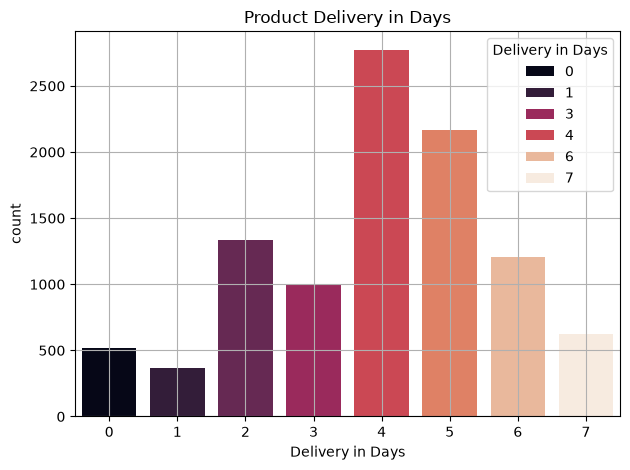

In [27]:
sns.countplot(x='Delivery in Days', data=df, palette='rocket', hue='Delivery in Days')
plt.title('Product Delivery in Days')
plt.grid()
plt.tight_layout()
plt.show()

In [28]:
df['Month'] = df['Order Date'].dt.month_name()

In [29]:
df['Year'] = df['Order Date'].dt.year

In [30]:
df['Month'].unique()

<StringArray>
[ 'November',      'June',   'October',     'April',  'December',       'May',
    'August',      'July', 'September',   'January',     'March',  'February']
Length: 12, dtype: str

In [31]:
df['Year'].unique()

array([2016, 2015, 2014, 2017], dtype=int32)

C:\Users\Shree\AppData\Local\Temp\ipykernel_11516\3620890416.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x='Month', y = 'Profit', data=df, marker = 'o', hue='Year', ci=None, palette='tab10')


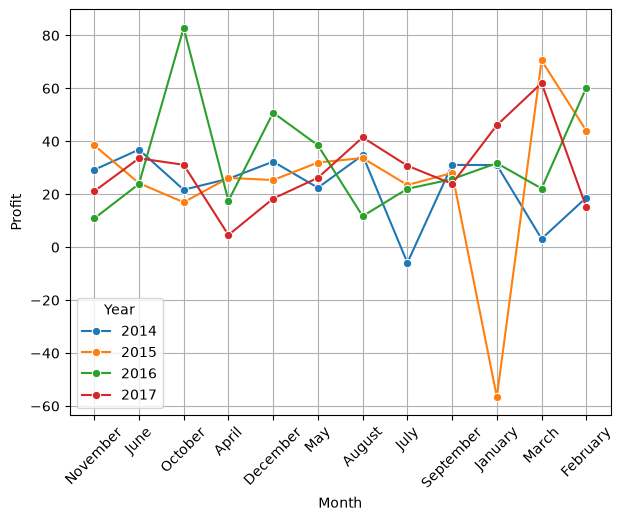

In [32]:
sns.lineplot(x='Month', y = 'Profit', data=df, marker = 'o', hue='Year', ci=None, palette='tab10')
plt.tight_layout()
plt.grid()
plt.xticks(rotation=45)
plt.show()

In [33]:
df['City'].unique()

<StringArray>
[        'Henderson',       'Los Angeles',   'Fort Lauderdale',
           'Concord',           'Seattle',        'Fort Worth',
           'Madison',       'West Jordan',     'San Francisco',
           'Fremont',
 ...
        'Hagerstown',       'East Orange', 'Arlington Heights',
            'Oswego',       'Coon Rapids',      'San Clemente',
   'San Luis Obispo',        'Springdale',              'Lodi',
             'Mason']
Length: 531, dtype: str

In [34]:
corr = df.corr(numeric_only=True).round(2)
corr

,Sales,Quantity,Discount,Profit,Delivery in Days,Year
Sales,1.00,0.20,-0.03,0.48,-0.01,-0.01
Quantity,0.20,1.00,0.01,0.07,0.02,-0.01
Discount,-0.03,0.01,1.00,-0.22,0.00,-0.00
Profit,0.48,0.07,-0.22,1.00,-0.00,0.00
Delivery in Days,-0.01,0.02,0.00,-0.00,1.00,-0.02
Year,-0.01,-0.01,-0.00,0.00,-0.02,1.00


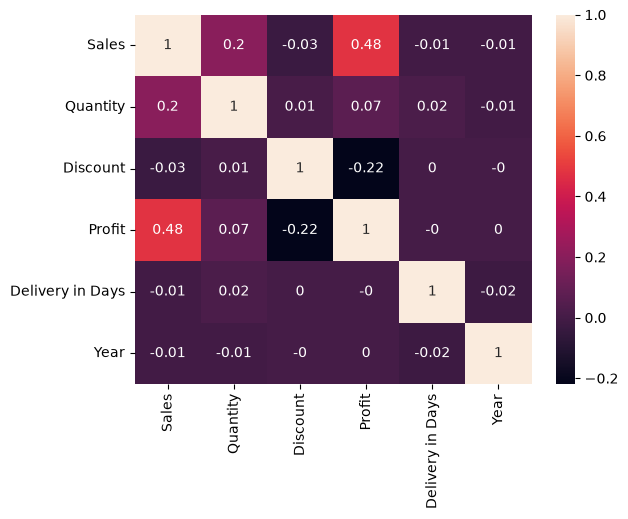

In [35]:
sns.heatmap(data=corr, annot=True)
plt.show()

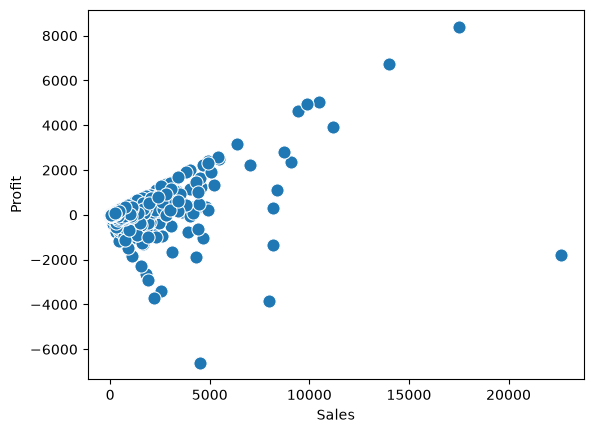

In [36]:
sns.scatterplot(x='Sales', y ='Profit', data=df, s=90)
plt.show()

## 8.Summary

#### 1. Mostly product Delivers in 4-5 Days
#### 2. in 2014 Hight profit in Augest Month and Low Profit in July Month
#### 3. In 2015 Hidhest Profit in March month and Low profit in Jan Month.
#### 4. In 2016 Highest Profit in Oct Month and Low profit in Aug Month.
#### 5. In 2017 Highest Profit in march Month and Low Profit in April Month.
#### 6. Overall In March Month We got Most profit.
#### 7. New York City Has MOst of Quantity was Sold.
